제조 AI 개인 프로젝트 제안서

(프로젝트 제목)

기존에 학습된 AI 모델과 Grad-CAM 기반 철강 표면 결함 자동 분류와 품질 검사 및 생산 공정 효율화 방안 연구

1. 과제 추진 배경 (Why)

해결하려는 제조 현장의 문제

~철강 제조 공정에서는 강철 표면 제품이 성질이 매우 다양하기 때문에 이를 예측하기 어려워서 균열등의 다양한 표면 결함이 발생합니다.육안 검사는 검사자의 숙련도와 작업 환경에 따라 판정 편차가 발생할 수 있으며,불량을 놓치는 경우 고객의 클레임과 재 작업 비용,신뢰성 하락이 발생합니다.~

철강 제조 공정에서는 수 많은 표면 결함들이 발생하는데 이는 육안 검사로는 정확하게 확인 하기 힘든 경우가 발생하기 때문에 철강산업의 경쟁력을 높이기 위해서는 자동 분류기가 필요합니다.

AI 적용의 필요성

~철강의 다양한 결함은 강판의 내식성과 강도에 치명적인 영향을 미치고 공장의 경제적 이익에도 악영향을 줍니다.따라서 표면 결함을 검출하는 것을 자동화 하는 알고리즘을 연구하는 것이 필수적입니다. 정확도, 정밀도, 재현율, F1-score 및 혼동 행렬을 활용하여 결함 별 분류 성능을 평가합니다.모델의 판단 근거를 직관적으로 설명할 수 있는 장점을 가진 Grad-CAM을 활용하여 모델이 결함을 분류할 때 중요하게 활용한 영역을 시각화를 한것을 토대로 판단하여.실제 결함을 정상으로 잘못 분류할 가능성에 대한 것을 유의하여 품질 검사의 개선점을 도출합니다.~

철강의 다양한 결함을 얼마나 잘 판별하는지에 따라 철강산업의 경쟁력에 영향을 줍니다.
따라서 표면 결함을 검출하는 것을 자동화 하는 알고리즘을 연구하는 것이 우리에게는 필수적입니다.
모델의 판단 근거를 직관적으로 설명할 수 있는 장점을 가진 Grad-CAM을 활용하여 실제 결함을 정상으로 잘못 분류할 가능성에 대한 것을 유의하여 품질 검사의 개선점을 도출합니다.

[A Survey of Vision-Based Methods for Surface Defects’ Detection and Classification in Steel Products](https://www.mdpi.com/2227-9709/11/2/25)
[Automatic Detection and Classification of Steel Surface Defect Using Deep Convolutional Neural Networks](https://www.mdpi.com/2075-4701/11/3/388)



2. 과제 소개 (What)
입력과 출력

입력:철강 표면 결함 이미지를 활용한 공개 데이터셋의 이미지를 모델 입력 크기인 224×224 픽셀로 변환하여 사용합니다.

출력:6개 결함 유형의 분류 결과 및 클래스별 예측 확률, 정확도.정밀도.재현율.F1-score 및 혼동 행렬을 활용한 품질 검사 성능 분석, 이미지당 AI 추론 시간의 측정을 통한 검사의 자동화 효율 분석, Grad-CAM 히트맵을 활용한 AI 판단 영역 시각화 및 오분류 사례 분석을 내놓습나다.

3. 과제 수행 방법 (How)

3.1. 데이터 수집 계획

데이터셋:NEU Surface Defect Database Dataset(Kaggle)

데이터구성:6개 결함 유형으로 구성되어있는 철강 표면 이미지 데이터셋을 활용합니다.

수집 방법:Google Colab 환경에서 데이터를 준비한 후 Python을 활용하여 이미지 파일과 클래스별 레이블을 불러옵니다.

데이터 분할:학습 데이터, 검증 데이터, 테스트 데이터를 70:15:15, 80:10:10, 60:20:20중에 가장 효과가잇는 것으로 분할한 후 각 결함 유형이 데이터 분할에 고르게 포함되도록 모집단을 특성에 따라 나누어 각 하위 집단에서 표본의 추출을 적용합니다.

NEU Surface Defect Database Dataset for classifying 6 types of surface defects
(https://www.kaggle.com/datasets/kaustubhdikshit/neu-surface-defect-database)

클래스별 데이터 분포


[70:15:15]
|label|학습	|검증 |	테스트 |
| :--- | :--- | :--- |:--- |
|crazing|210|45|45|
|inclusion|210|45|45|
|patches|	210	|45	|45|
|pitted_surface	|210	|45	|45|
|rolled-in_scale|210	|45	|45|
|scratches	|210|	45|	45|


[80:10:10]
|label|학습	|검증 |	테스트 |
| :--- | :--- | :--- |:--- |
crazing	|240	|30	|30
inclusion	|240	|30	|30
patches	|240	|30	|30
pitted_surface|	240|	30	|30
rolled-in_scale	|240	|30	|30
scratches	|240|	30|	30

[60:20:20]
|label|학습	|검증 |	테스트 |
| :--- | :--- | :--- |:--- |
crazing|180	|60	|60
inclusion|	180|	60	|60
patches|180	|60	|60
pitted_surface|	180	|60	|60
rolled-in_scale|	180|	60	|60
scratches	|180	|60	|60










3.2. 데이터 전처리

이미지 분할 및 전이 학습 및 미세 조정에 적합해야 하며 각도, 위치, 크기의 영향이 작아야 합니다.따라서 아래와 같은 방법을 선택하였습니다.

~이미지 전처리:224×224 RGB 변환 및 MobileNetV2 규격 정규화(Rescaling(1/127.5,offset=-1)) 적용합니다.~

~데이터 증강:좌우 반전(RandomFlip),미세 회전(RandomRotation(0.05)),미세 Zoom(RandomZoom(0.1))을 선별 적용하여 조정하면서 일반화 성능을 향상시킴과 동시에 수직 반전 및 90도 회전은 배제합니다.~

~데이터 누출 방지:증강 파이프라인은 학습 데이터 세트에만 적용하고 검증 및 테스트 세트는 원본을 유지합니다.~

tf.keras.applications.MobileNetV2
(https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2?)


이미지 전처리:224×224크기 변경, 특징을 최대한 훼손하지 않기 위해서 명암 기반 TURBO 컬러 매핑 기법을 사용하여 RGB 변환 및 MobileNetV2 규격 정규화(Rescaling(1/127.5,offset=-1)) 적용합니다.
또한 좌우 반전(RandomFlip),미세 회전을 10.8도 미세회전으로 바꿀시 모서리 여백 감소 효과를 위하여 (RandomRotation(0.03))으로 설정,미세 Zoom(RandomZoom(0.1))을 선별 적용하여 조정하면서 일반화 성능을 향상시킴과 동시에 결함의 방향성이 왜곡됨을 방지하기 위해 수직 반전 및 90도 회전은 배제합니다.

데이터 증강:데이터 누출 방지를 위하여 증강 파이프라인은 학습 데이터 세트에만 적용하고 검증 및 테스트 세트는 원본을 유지합니다.

데이터 증강 적용되는 범위: 좌우반전, 미세회전, 확대 및 축소

데이터 증강 적용되지 않는 범위(전처리): RGB변환, 정규화, TURBO 컬러 매핑, 이미지 크기 변경 (224X224)


전처리 결과 이미지 크기: (224, 224, 3)
자료형: <dtype: 'float32'>
최솟값: -0.5341737
최댓값: 1.0
RGB 채널 크기: (224, 224, 3)

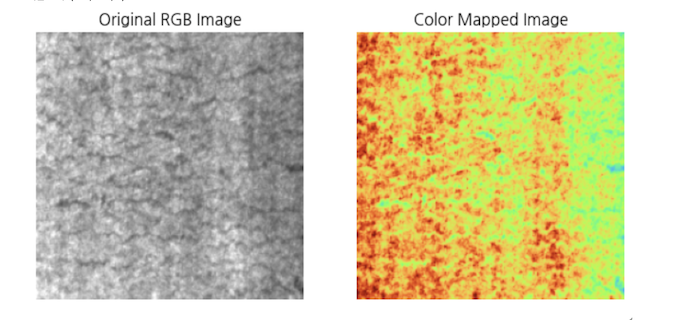

파이프라인 생성

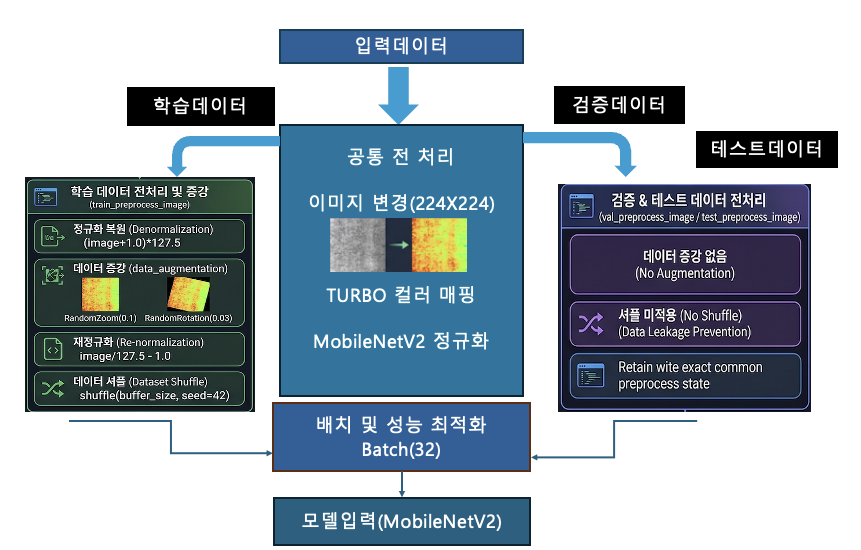


파이프라인 설명

1. 공통 전처리

입력된 모든 이미지를 224×224로 규격화한 뒤 TURBO 컬러 매핑과 MobileNetV2 정규화를 일괄 적용하여 학습, 검증, 테스트 데이터가 동일한 출발선과 해상도, 색상, 스케일을 공유하도록 만들게 하여 이후 단계에서 공정한 비교와 평가가 가능하게 합니다.

2-1. 학습데이터 전처리 및 증강

학습 데이터는 정규화 복원 후 무작위 확대및 회전을 적용하는 데이터 증강및  재정규화, 그리고 셔플을 거쳐 모델의 일반화 성능을 높입니다. 이는 학습용 데이터와 검증 및 테스트 데이터를 를 엄격히 격리하는 분기 단계의 핵심 과정입니다.

2-2. 검증 및 테스트 데이터 전처리

검증 및 테스트 데이터는 인위적인 데이터 증강과 셔플을 모두 배제하여 공통 전처리를 마친 원본 상태를 그대로 유지합니다. 이를 통해 학습 과정에서 평가 데이터가 섞이거나 변형되는 데이터 누수를 차단하고, 모델의 실제 성능을 객관적으로 검증 및 평가하는 역할을 수행합니다.


3. 배치 및 성능 최적화 Batch(32)

앞선 단계에서 규격은 통일되고 목적에 따라 분리 처리된 세 데이터셋을 각각 독립된 32개 단위의 배치(Batch(32))로 묶어 MobileNetV2 모델에 입력합니다. 이를 통해 연산 효율을 극대화하는 동시에, 세 데이터가 서로 간섭 없이 가중치 업데이트, 과적합 점검, 최종 테스트 역할을 정확히 수행하도록 연결합니다.



3.3. 모델 설계 및 학습

1.학습된 MobileNetV2 을 선택하여 사전 학습 모델을 한다.

~2.이미 학습된 신경망의 파라미터가 더 이상 업데이트되지 않도록 고정한 (trainable=False), GAP+Dropout(0.2), 파리미터 조정 가능한 Dense(6,Softmax)헤드를 결합하여 학습합니다.~

2.이미 학습된 신경망의 파라미터가 더 이상 업데이트되지 않도록 고정한 후 Input(shape=(224,224,3))의 분류기를 구성하여 (trainable=False), GAP+Dropout(0.2), 파리미터 조정 가능한 Dense(6,Softmax)헤드를 결합하여 학습합니다.

2-1.학습 분할 비율별 전이학습을 실시하여 가장 좋은 분할 비율을 선택합니다.

3.증강단계 에서는 Data Augmentation 파이프라인 추가 적용 후 과적합 완화 및 성능 변화 비교 실험을 진행합니다.

~4.조정 단게에서는 상위 Conv 신경망의 특정 층이 학습 중 가중치를 업데이트하지 못하도록 고정한 것을 해제 및 미세 학습률(lr=1e-5) 재학습을 통한 최적화를 합니다.~

4.조정 단게에서는 데이터 증강 여부를 결정하고 제한된 학습 데이터에서 과적합을 줄이고 모델의 일반화 성능을 확보하기 위해 상위 Conv 신경망에서 상위 25개 층만 학습 가능하도록 설정 한 후 특정 층이 학습 중 가중치를 업데이트하지 못하도록 고정한 것을 해제 및 미세 학습률(lr=1e-5) 재학습을 통한 조기 종료를 통한 최적화를 합니다.

|분할 비율(Epoch=15/15)|70:15:15|80:10:10|60:20:20|
|---|---:|---:|---:|
accuracy| 0.9937 | 0.9944 |0.9907|
loss| 0.0306 |0.0293|0.0406|
val_accuracy| 0.9889 |1.0000 |0.9917|
val_loss| 0.0426|0.0248|0.0428|
Epoch당 평균 학습 시간(초)|18|19|16|

선택할 분할 비율 80:10:10

val_loss(검증손실)에서 0.0248로 압도적으로 낮아서 학습에 사용하지 않은 데이터에서도 모델이 얼마나 안정적으로 가장 잘 예측합니다. 그리고 val_accuracy(검증 정확도)에서 1.00으로 가장 높다.에포크당 평균 학습 시간은 19초로 가장 길지만 검증손실과 검증 정확도에서 뛰어나기 때문에 이를 감안 할 수 있습니다.


80:10:10 성능 비교
구분|증강적용|증강미적용|
|---|---:|---:|
|정확도|0.9944|1.0000
|손실|0.0281|0.0185


증강을 미적용한 것의 정확도는 1, 평균 Epoch시간은 4.3초 손실이 0.0185로 더 낮기 때문에 증강 미적용한 손실을 선택합니다.

3.4. 성능 평가

정량적 평가지표:정확도, 정밀도, 재현율, F1-score 및 6×6 혼동 행렬을 산출하여 클래스별 분류 성능 및 오분류 경향을 정밀 분석합니다.

공정 적용성 평가:이미지 1장당 AI 추론 시간(ms)을 측정하여 실시간 생산 라인 적용 가능성을 검증합니다.

~XAI 시각적 검증:Grad-CAM 히트맵을 통해 모델이 결함으로 판단한 핵심 영역을 시각화하고,실제 결함 위치와의 일치 여부 및 Shortcut Learning 발생 여부를 판정합니다.~

XAI 시각적 검증:Grad-CAM 히트맵을 통해 모델이 결함으로 판단한 핵심 영역을 시각화하고,원본과 Grad-CAM히트맵을 겹치는 over lay를 통한 실제 결함 위치와의 일치 여부를 판정합니다.

[Grad-CAM 기반 딥러닝 분류 모델을 활용한 강판 표면 결함의 비파괴 시각화 기법](https://www.kci.go.kr/kciportal/ci/sereArticleSearch/ciSereArtiView.kci?sereArticleSearchBean.artiId=ART003227886)


[grad-cam enabled breast cancer classification with a 3d inception-resnet v2: empowering radiologists with explainable insights (2024)](https://www.mdpi.com/2072-6694/16/21/3668#Experimental_Results_a6)

   성능 평가 정량적 평가지표     
        
        
 |구분|precision|recall|f1-score |support|
 |---|---:|---:|---:|---:|
crazing  |   1.0000   | 1.0000  |  1.0000      |  30
inclusion  |    1.0000  |   1.0000  |   1.0000    |     30
patches   |   1.0000  |   1.0000  |   1.0000   |      30
pitted_surface  |    1.0000 |   1.0000   |  1.0000    |     30
rolled-in_scale   |   1.0000  |   1.0000   |  1.0000   |      30
scratches   |   1.0000 |    1.0000   |  1.0000     |    30


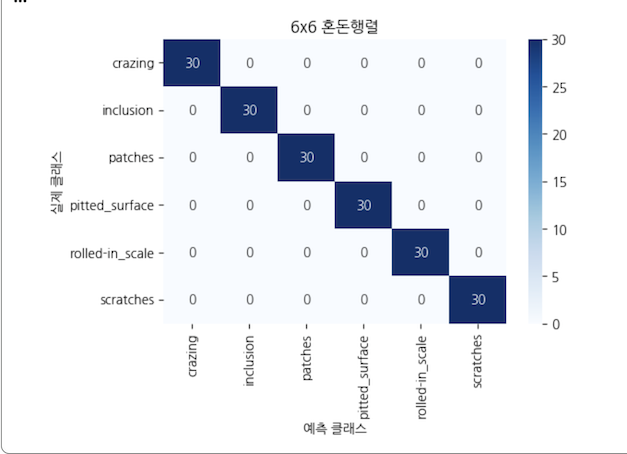



혼동행렬 분석결과:대각선 말고 다른부분이 0이 나와서 모든 클래스에서 실제 클래스와 예측 클래스가 일치한다.
그리고 f1 스코어가 높게 나와 모델이 결함을 정확하게 분류하면서 실제 결함을 놓치는 경우가 매우 적다고 판단합니다.

공정 적용성 평가

이미지 1장당 평균 추론 시간:6.3901 ms

XAI 시각적 검증

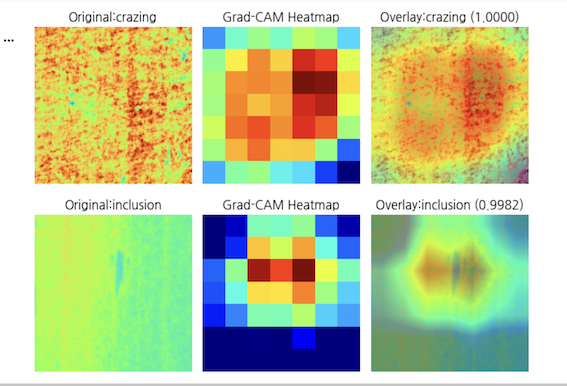



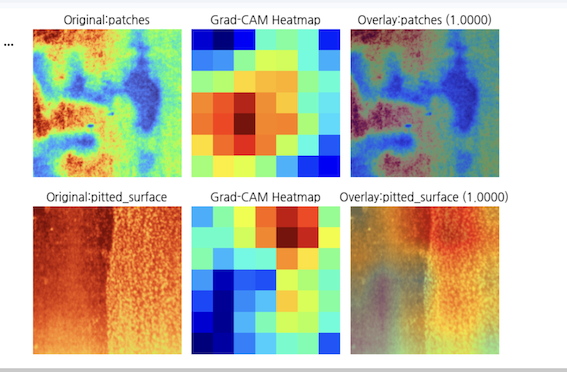

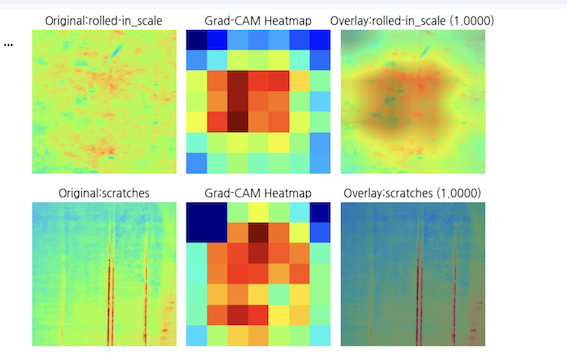

Grad-CAM 분석결과
inclusion, scratches: 좁은 부분 결함의 정밀 포착

crazing, patches, rolled-in_scale, pitted_surface: 광범위 영역 결함의 포착

Grad-CAM 개선방향:기존 tf.reduce_mean(grads)는 넓은 단일 영역에만 집중하는 경향이 있습니다. 따라서 2차, 3차 미분항을 근사한 Grad-CAM++ 가중치를 적용하여 광범위 영역 결함의 포착의 정확도를 높입니다.

[Grad-CAM++: Improved Visual Explanations for Deep Convolutional Networks](https://ieeexplore.ieee.org/document/8354201)

4. 기대효과 (Result)

품질 검사 자동화 및 비용 절감:육안 검사의 판정 편차를 해소하고,실제로는 결함이 존재하나 모델이 해당 결함을 제대로 검출하지 못한 경우로 인한 고객 클레임 비용 및 불필요한 재작업 및 폐기 비용을 대폭 절감합니다.

생산 공정 효율화:빠른 추론 속도를 바탕으로 표면 결함을 실시간 자동 검출하여 생산 공정의 순환 주기를 단축시킵니다.

AI 판단 신뢰성 확보:Grad-CAM 기반 시각적 근거를 제공하여 현장 작업자의 AI 수용성을 높이고 잘못 분리하는 상황 발생 시 신속한 원인 규명이 가능해집니다.

결함 대응 범위 확대:새로운 특징 데이터가 발생해도 재학습이 간단하여 범용성이 뛰어난 딥러닝의 특성을 불균일에 의하여 다양한 클래스내 다양성을 가지는 철강에 적합합니다.

[딥러닝 및 전이학습을 이용한 표면결함 분류에 관한 연구](https://chains.dcollection.net/public_resource/pdf/200000173846_20261021024921.pdf)

5. 추진 일정

| 주차 | 수행 내용 | 결과물 |
|---|---|---|
9주차 | NEU 데이터셋 수집 및 비율별 데이터 분할 | 데이터 구성 및 EDA 결과
| 10주차 | MobileNetV2 사전학습 모델 구축 및 백본 동결 학습 | Baseline 학습 코드 및 학습 곡선 |
| 11주차 | Data Augmentation 파이프라인 추가 및 전후 비교 실험 | 증강 전후 비교 실험 보고서 |
| 12주차 | 미세조정 적용 및 6×6 혼동 행렬 분석 | 성능 평가 지표 및 혼동 행렬 |
| 13주차 | Grad-CAM 파이프라인 구축 및 히트맵 시각화 검증 | Grad-CAM 히트맵 시각화 결과물 |
| 14주차 | Grad-CAM 성능 개선 | 최종 결과 분석 리포트 |
| 15주차 | 프로젝트 최종 보고서 작성, 제출 및 발표 | 최종 보고서 |


6. 참고 자료

- 데이터: [NEU Surface Defect Database
Dataset for classifying 6 types of surface defects](https://www.kaggle.com/datasets/kaustubhdikshit/neu-surface-defect-database)
- 관련 사례·논문·문서: [A Survey of Vision-Based Methods for Surface Defects’ Detection and Classification in Steel Products](https://www.mdpi.com/2227-9709/11/2/25)
- [Automatic Detection and Classification of Steel Surface Defect Using Deep Convolutional Neural Networks](https://www.mdpi.com/2075-4701/11/3/388)
- [Grad-CAM 기반 딥러닝 분류 모델을 활용한 강판 표면 결함의 비파괴 시각화 기법](https://www.kci.go.kr/kciportal/ci/sereArticleSearch/ciSereArtiView.kci?sereArticleSearchBean.artiId=ART003227886)
- [tf.keras.applications.MobileNetV2](https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2?)
- [딥러닝 및 전이학습을 이용한 표면결함 분류에 관한 연구](https://chains.dcollection.net/public_resource/pdf/200000173846_20261021024921.pdf)
- [grad-cam enabled breast cancer classification with a 3d inception-resnet v2: empowering radiologists with explainable insights (2024) ](https://www.mdpi.com/2072-6694/16/21/3668#Experimental_Results_a6)
-[Grad-CAM++: Improved Visual Explanations for Deep Convolutional Networks](https://ieeexplore.ieee.org/document/8354201)